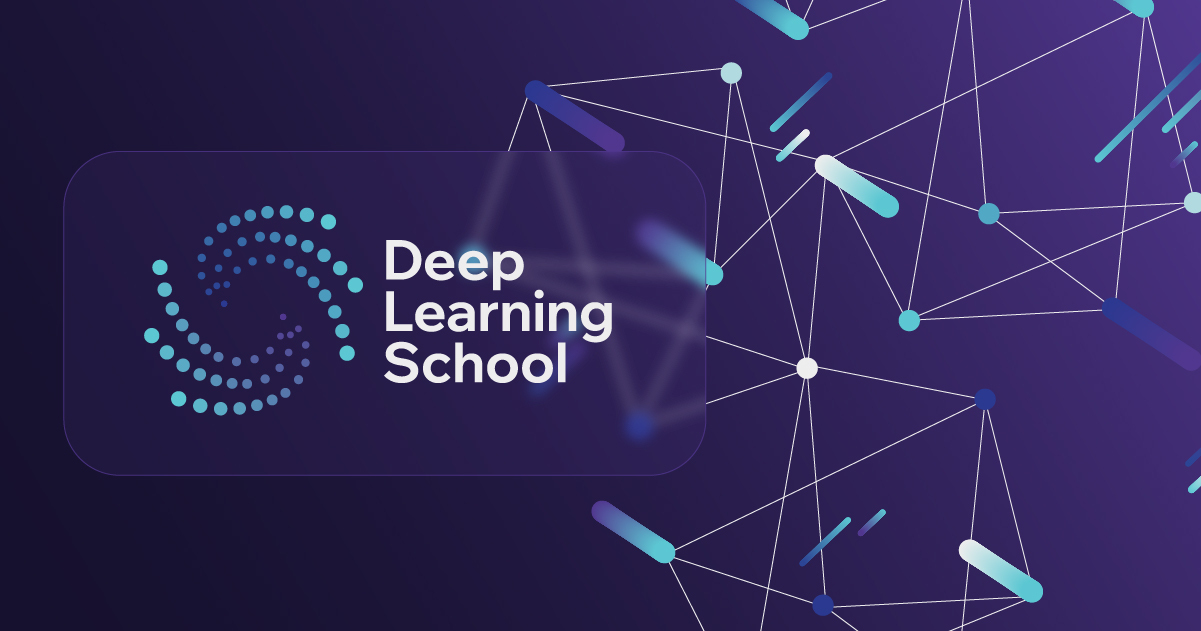

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание. Нейросетевая классификация текстов </b></h1>

В этом домашнем задании вам предстоит самостоятельно решить задачу классификации текстов на основе семинарского кода. Мы будем использовать датасет [ag_news](https://paperswithcode.com/dataset/ag-news). Это датасет для классификации новостей на 4 темы: "World", "Sports", "Business", "Sci/Tech".

Установим модуль datasets, чтобы нам проще было работать с данными.

Импорт необходимых библиотек

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import datasets
import copy
import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from datasets import load_dataset
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
import nltk

from collections import Counter
from typing import List
import string

import seaborn
seaborn.set(palette='summer')

In [2]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [3]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

## Подготовка данных
Для вашего удобства, мы привели код обработки датасета в ноутбуке. Ваша задача --- обучить модель, которая получит максимальное возможное качество на тестовой части.

In [4]:
# Загрузим датасет
dataset = datasets.load_dataset('fancyzhx/ag_news')

Как и в семинаре, выполним следующие шаги:
* Составим словарь
* Создадим класс WordDataset
* Выделим обучающую и тестовую часть, создадим DataLoader-ы.

In [5]:
words = Counter()

for example in tqdm(dataset['train']['text']):
    # Приводим к нижнему регистру и убираем пунктуацию
    prccessed_text = example.lower().translate(
        str.maketrans('', '', string.punctuation))

    for word in word_tokenize(prccessed_text):
        words[word] += 1


vocab = set(['<unk>', '<bos>', '<eos>', '<pad>'])
counter_threshold = 25

for char, cnt in words.items():
    if cnt > counter_threshold:
        vocab.add(char)

print(f'Размер словаря: {len(vocab)}')

word2ind = {char: i for i, char in enumerate(vocab)}
ind2word = {i: char for char, i in word2ind.items()}

  0%|          | 0/120000 [00:00<?, ?it/s]

Размер словаря: 11842


In [6]:
class WordDataset:
    def __init__(self, sentences):
        self.data = sentences
        self.unk_id = word2ind['<unk>']
        self.bos_id = word2ind['<bos>']
        self.eos_id = word2ind['<eos>']
        self.pad_id = word2ind['<pad>']

    def __getitem__(self, idx: int) -> List[int]:
        processed_text = self.data[idx]['text'].lower().translate(
            str.maketrans('', '', string.punctuation))
        tokenized_sentence = [self.bos_id]
        tokenized_sentence += [
            word2ind.get(word, self.unk_id) for word in word_tokenize(processed_text)
            ]
        tokenized_sentence += [self.eos_id]

        train_sample = {
            "text": tokenized_sentence,
            "label": self.data[idx]['label']
        }

        return train_sample

    def __len__(self) -> int:
        return len(self.data)


def collate_fn_with_padding(
    input_batch: List[List[int]], pad_id=word2ind['<pad>'], max_len=256) -> torch.Tensor:
    seq_lens = [len(x['text']) for x in input_batch]
    max_seq_len = min(max(seq_lens), max_len)

    new_batch = []
    for sequence in input_batch:
        sequence['text'] = sequence['text'][:max_seq_len]
        for _ in range(max_seq_len - len(sequence['text'])):
            sequence['text'].append(pad_id)

        new_batch.append(sequence['text'])

    sequences = torch.LongTensor(new_batch).to(device)
    labels = torch.LongTensor([x['label'] for x in input_batch]).to(device)

    new_batch = {
        'input_ids': sequences,
        'label': labels
    }

    return new_batch

In [7]:
train_dataset = WordDataset(dataset['train'])

np.random.seed(42)
idx = np.random.choice(np.arange(len(dataset['test'])), 5000)
eval_dataset = WordDataset(dataset['test'].select(idx))

batch_size = 32
train_dataloader = DataLoader(
    train_dataset, shuffle=True, collate_fn=collate_fn_with_padding, batch_size=batch_size)

eval_dataloader = DataLoader(
    eval_dataset, shuffle=False, collate_fn=collate_fn_with_padding, batch_size=batch_size)

## Постановка задачи
Ваша задача -- получить максимальное возможное accuracy на `eval_dataloader`. Ниже приведена функция, которую вам необходимо запустить для обученной модели, чтобы вычислить качество её работы.

In [8]:
def evaluate(model, eval_dataloader) -> float:
    """
    Calculate accuracy on validation dataloader.
    """

    predictions = []
    target = []
    with torch.no_grad():
        for batch in eval_dataloader:
            logits = model(batch['input_ids'])
            predictions.append(logits.argmax(dim=1))
            target.append(batch['label'])

    predictions = torch.cat(predictions)
    target = torch.cat(target)
    accuracy = (predictions == target).float().mean().item()

    return accuracy

## Ход работы
Оценка за домашнее задание складывается из четырех частей:



### Запуск базовой модели с семинара на новом датасете (1 балл)
На семинаре мы создали модель, которая дает на нашей задаче довольно высокое качество. Ваша цель --- обучить ее и вычислить `score`, который затем можно будет использовать в качестве бейзлайна.

В модели появится одно важное изменение: количество классов теперь равно не 2, а 4. Обратите на это внимание и найдите, что в коде создания модели нужно модифицировать, чтобы учесть это различие.

При инициализации модели за количество классов на выходе отвечается параметр `num_classes`, мы изменили его на 4, так как у нас 4 типа статей

In [9]:
class CharLM(nn.Module):
    def __init__(
        self, hidden_dim: int, vocab_size: int, num_classes: int = 4,
        aggregation_type: str = 'max', rnn_type: str = 'rnn',
        num_layers: int = 1
        ):
        super().__init__()
        rnn_cls = {'rnn': nn.RNN, 'gru': nn.GRU, 'lstm': nn.LSTM}[rnn_type]
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = rnn_cls(hidden_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, num_classes)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

        self.aggregation_type = aggregation_type

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)  # [batch_size, seq_len, hidden_dim]
        output, _ = self.rnn(embeddings)  # [batch_size, seq_len, hidden_dim]

        if self.aggregation_type == 'max':
            output = output.max(dim=1)[0] #[batch_size, hidden_dim]
        elif self.aggregation_type == 'mean':
            output = output.mean(dim=1) #[batch_size, hidden_dim]
        else:
            raise ValueError("Invalid aggregation_type")

        output = self.dropout(self.linear(self.non_lin(output)))  # [batch_size, hidden_dim]
        prediction = self.projection(self.non_lin(output))  # [batch_size, num_classes]

        return prediction

In [10]:
model = CharLM(hidden_dim=256, vocab_size=len(vocab)).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(model.parameters())

In [11]:
num_epoch = 5
eval_steps = len(train_dataloader) // 2


losses_type = {}
acc_type = {}

for aggregation_type in ['max', 'mean']:
    print(f"Starting training for {aggregation_type}")
    losses = []
    acc = []

    model = CharLM(
        hidden_dim=256, vocab_size=len(vocab), aggregation_type=aggregation_type).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters())

    for epoch in range(num_epoch):
        epoch_losses = []
        model.train()
        for i, batch in enumerate(tqdm(train_dataloader, desc=f'Training epoch {epoch}:')):
            optimizer.zero_grad()
            logits = model(batch['input_ids'])
            loss = criterion(logits, batch['label'])
            loss.backward()
            optimizer.step()

            epoch_losses.append(loss.item())
            if i % eval_steps == 0:
                model.eval()
                acc.append(evaluate(model, eval_dataloader))
                model.train()

        losses.append(sum(epoch_losses) / len(epoch_losses))

    losses_type[aggregation_type] = losses
    acc_type[aggregation_type] = acc

Starting training for max


Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 4::   0%|          | 0/3750 [00:00<?, ?it/s]

... (2 outputs left out)

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 4::   0%|          | 0/3750 [00:00<?, ?it/s]

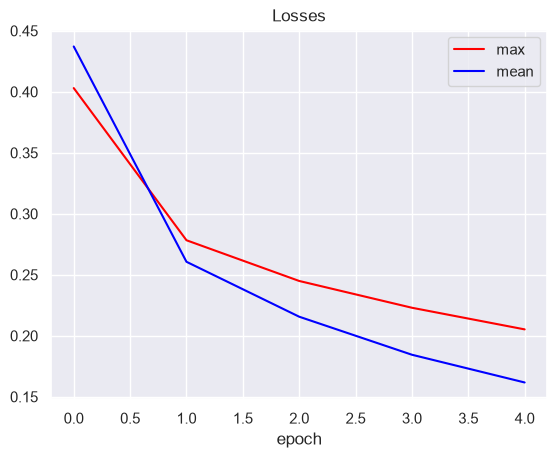

In [12]:
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    plt.plot(np.arange(len(losses_type[name])), losses_type[name], color=color, label=name)

plt.title('Losses')
plt.xlabel("epoch")
plt.legend()
plt.show()

Лучшая accuracy для подхода max: 90.32
Лучшая accuracy для подхода mean: 90.86


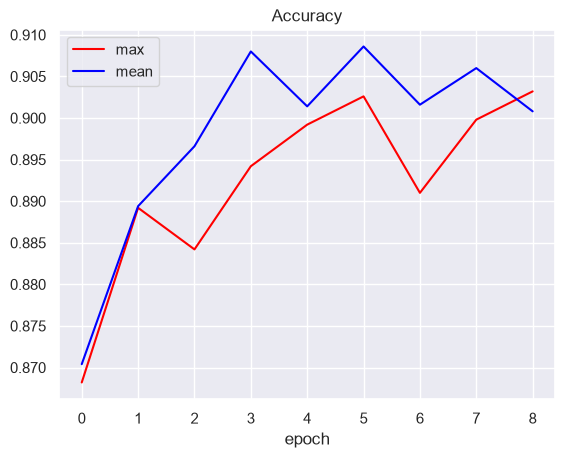

In [13]:
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    plt.plot(np.arange(len(acc_type[name][1:])), acc_type[name][1:], color=color, label=name)
    print(f"Лучшая accuracy для подхода {name}: {(max(acc_type[name]) * 100):.2f}")

plt.title('Accuracy')
plt.xlabel("epoch")
plt.legend()
plt.show()

### Проведение экспериментов по улучшению модели (2 балла за каждый эксперимент)
Чтобы улучшить качество базовой модели, можно попробовать различные идеи экспериментов. Каждый выполненный эксперимент будет оцениваться в 2 балла. Для получения полного балла за этот пункт вам необходимо выполнить по крайней мере 2 эксперимента. Не расстраивайтесь, если какой-то эксперимент не дал вам прироста к качеству: он все равно зачтется, если выполнен корректно.

Вот несколько идей экспериментов:
* **Модель RNN**. Попробуйте другие нейросетевые модели --- LSTM и GRU. Мы советуем обратить внимание на [GRU](https://pytorch.org/docs/stable/generated/torch.nn.GRU.html), так как интерфейс этого класса ничем не отличается от обычной Vanilla RNN, которую мы использовали на семинаре.
* **Увеличение количества рекуррентных слоев модели**. Это можно сделать с помощью параметра `num_layers` в классе `nn.RNN`. В такой модели выходы первой RNN передаются в качестве входов второй RNN и так далее.
* **Изменение архитектуры после применения RNN**. В базовой модели используется агрегация со всех эмбеддингов. Возможно, вы захотите конкатенировать результат агрегации и эмбеддинг с последнего токена.
* **Подбор гиперпараметров и обучение до сходимости**. Возможно, для получения более высокого качества просто необходимо увеличить количество эпох обучения нейросети, а также попробовать различные гиперпараметры: размер словаря, `dropout_rate`, `hidden_dim`.

Обратите внимание, что главное правило проведения экспериментов --- необходимо совершать одно архитектурное изменение в одном эксперименте. Если вы совершите несколько изменений, то будет неясно, какое именно из изменений дало прирост к качеству.

In [ ]:
def plot_results(results):
    _, axes = plt.subplots(1, 2, figsize=(12, 4))
    for name, r in results.items():
        axes[0].plot(r['losses'], label=name)
        axes[1].plot(r['acc'], label=name)
        print(f"{name}: лучшая accuracy {r['best_acc'] * 100:.2f}")
    axes[0].set_title('Loss'); axes[0].set_xlabel('epoch')
    axes[1].set_title('Accuracy'); axes[1].set_xlabel('eval step (2 за эпоху)')
    for ax in axes:
        ax.legend()
    plt.show()

#### Тестирование GRU и LSTM

In [15]:


def train(rnn_type, aggregation_type, num_layers=1, num_epoch=5, seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    model = CharLM(hidden_dim=256, vocab_size=len(vocab), aggregation_type=aggregation_type,
                   rnn_type=rnn_type, num_layers=num_layers).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters())
    eval_steps = len(train_dataloader) // 2
    losses, acc = [], []
    best_acc, best_state = 0.0, None
    name = f'{rnn_type}/{aggregation_type}/L{num_layers}/s{seed}'

    for epoch in range(num_epoch):
        epoch_losses = []
        model.train()
        for i, batch in enumerate(tqdm(train_dataloader, desc=f'{name} epoch {epoch}')):
            optimizer.zero_grad()
            loss = criterion(model(batch['input_ids']), batch['label'])
            loss.backward()
            optimizer.step()
            epoch_losses.append(loss.item())
            if i % eval_steps == 0:
                model.eval()
                acc.append(evaluate(model, eval_dataloader))
                if acc[-1] > best_acc:
                    best_acc, best_state = acc[-1], copy.deepcopy(model.state_dict())
                model.train()
        losses.append(sum(epoch_losses) / len(epoch_losses))
    return {'losses': losses, 'acc': acc, 'best_acc': best_acc, 'best_state': best_state,
            'config': dict(rnn_type=rnn_type, aggregation_type=aggregation_type,
                           num_layers=num_layers, seed=seed)}




results = {}
for rnn_type in ['rnn', 'gru', 'lstm']:
    for agg in ['max', 'mean']:
        results[f'{rnn_type}/{agg}'] = train(rnn_type, agg)


rnn/max/L1/s42 epoch 0:   0%|          | 0/3750 [00:00<?, ?it/s]

rnn/max/L1/s42 epoch 1:   0%|          | 0/3750 [00:00<?, ?it/s]

rnn/max/L1/s42 epoch 2:   0%|          | 0/3750 [00:00<?, ?it/s]

rnn/max/L1/s42 epoch 3:   0%|          | 0/3750 [00:00<?, ?it/s]

rnn/max/L1/s42 epoch 4:   0%|          | 0/3750 [00:00<?, ?it/s]

rnn/mean/L1/s42 epoch 0:   0%|          | 0/3750 [00:00<?, ?it/s]

... (20 outputs left out)

lstm/mean/L1/s42 epoch 1:   0%|          | 0/3750 [00:00<?, ?it/s]

lstm/mean/L1/s42 epoch 2:   0%|          | 0/3750 [00:00<?, ?it/s]

lstm/mean/L1/s42 epoch 3:   0%|          | 0/3750 [00:00<?, ?it/s]

lstm/mean/L1/s42 epoch 4:   0%|          | 0/3750 [00:00<?, ?it/s]

rnn/max: лучшая accuracy 91.22
rnn/mean: лучшая accuracy 90.82
gru/max: лучшая accuracy 91.46
gru/mean: лучшая accuracy 91.10
lstm/max: лучшая accuracy 91.22
lstm/mean: лучшая accuracy 91.44


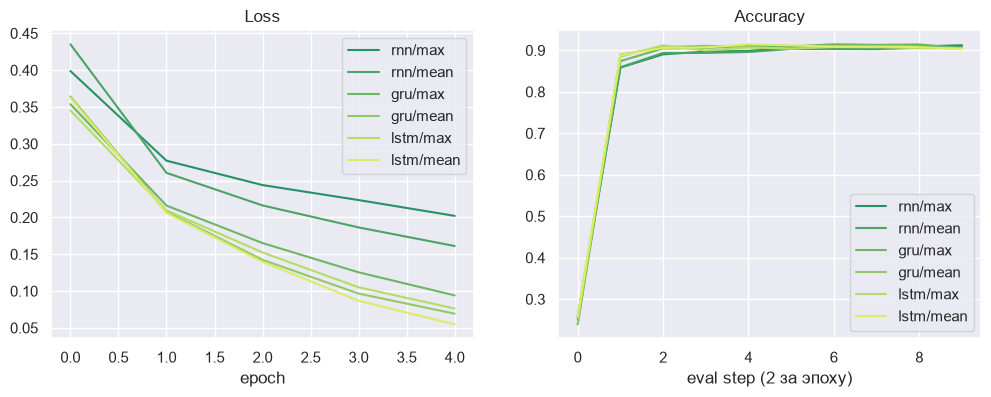

In [16]:
plot_results(results)


#### Тестирование числа рекуррентных слоев

lstm/mean/L1/s42 epoch 0:   0%|          | 0/3750 [00:00<?, ?it/s]

lstm/mean/L1/s42 epoch 1:   0%|          | 0/3750 [00:00<?, ?it/s]

lstm/mean/L1/s42 epoch 2:   0%|          | 0/3750 [00:00<?, ?it/s]

lstm/mean/L1/s42 epoch 3:   0%|          | 0/3750 [00:00<?, ?it/s]

lstm/mean/L1/s42 epoch 4:   0%|          | 0/3750 [00:00<?, ?it/s]

lstm/mean/L2/s42 epoch 0:   0%|          | 0/3750 [00:00<?, ?it/s]

lstm/mean/L2/s42 epoch 1:   0%|          | 0/3750 [00:00<?, ?it/s]

lstm/mean/L2/s42 epoch 2:   0%|          | 0/3750 [00:00<?, ?it/s]

lstm/mean/L2/s42 epoch 3:   0%|          | 0/3750 [00:00<?, ?it/s]

lstm/mean/L2/s42 epoch 4:   0%|          | 0/3750 [00:00<?, ?it/s]

lstm/mean/L1: лучшая accuracy 91.44
lstm/mean/L2: лучшая accuracy 91.68


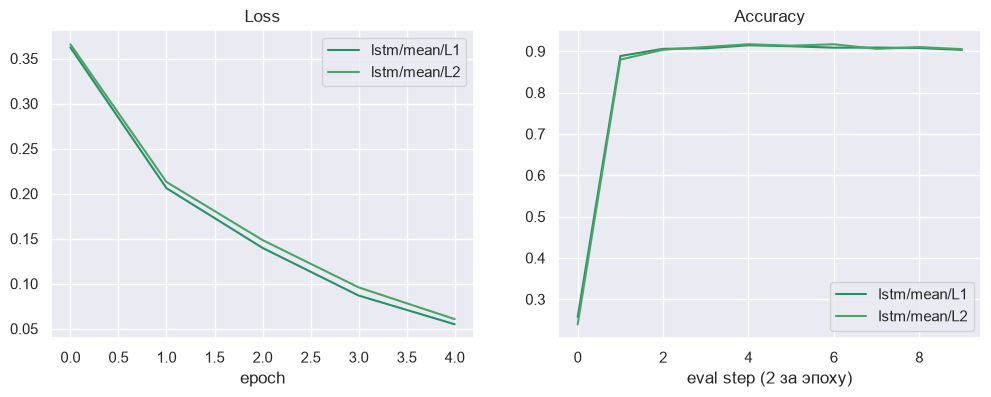

In [17]:
results_layers = {}
for num_layers in [1, 2]:
    results_layers[f'lstm/mean/L{num_layers}'] = train('lstm', 'mean', num_layers=num_layers)

plot_results(results_layers)

(L1/L2 - количество рекурентных слоев )

#### Итоговая модель
Восстанавливаем веса лучшей модели и считаем accuracy функцией `evaluate`.

In [18]:
all_results = {**results, **results_layers}
best_name = max(all_results, key=lambda k: all_results[k]['best_acc'])
best = all_results[best_name]

best_model = CharLM(hidden_dim=256, vocab_size=len(vocab),
                    aggregation_type=best['config']['aggregation_type'],
                    rnn_type=best['config']['rnn_type'],
                    num_layers=best['config']['num_layers']).to(device)
best_model.load_state_dict(best['best_state'])
best_model.eval()

print(f"best: {best_name}")
print(f"acc (eval): {evaluate(best_model, eval_dataloader):.4f}")


best: lstm/mean/L2
acc (eval): 0.9168


### Получение высокого качества (3 балла)
В конце вашей работы вы должны указать, какая из моделей дала лучший результат, и вывести качество, которое дает лучшая модель, с помощью функции `evaluate`. Ваша модель будет оцениваться по метрике `accuracy` следующим образом:
* $accuracy < 0.9$ --- 0 баллов;
* $0.9 \leqslant accuracy < 0.91$ --- 1 балл;
* $0.91 \leqslant accuracy < 0.915$ --- 2 балла;
* $0.915 \leqslant accuracy$ --- 3 балла.

### Оформление отчета (2 балла)
В конце работы подробно опишите все проведенные эксперименты.
* Укажите, какие из экспериментов принесли улучшение, а какие --- нет.
* Проанализируйте графики сходимости моделей в проведенных экспериментах. Являются ли колебания качества обученных моделей существенными в зависимости от эпохи обучения, или же сходимость стабильная?
* Укажите, какая модель получилась оптимальной.

Желаем удачи!

По сути был простой перебор по сетке где параметрами выступали виды rnn-ок (classic-rnn, gru, lstm), а также количество слоев 1 и 2. Из всех таких комбинаций лучшей оказалась `lstm/mean/L2` с агрегацией mean